In [115]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [116]:
L = 80*1e-3
C = 1e-6
RL = 0.0
table = pd.DataFrame(
    index=[1, 2, 3],
    data={
        "R1": [40, 80, 120],
        "dt": [1.8 * 1e-3, 1.84 * 1e-3, 1.88 * 1e-3],
        "A1": [2.7, 1.44, 1.0],
        "A2": [1.65, 0.6, 0.32],
    },
)
table

,R1,dt,A1,A2
1,40,0.00180,2.70,1.65
2,80,0.00184,1.44,0.60
3,120,0.00188,1.00,0.32


In [134]:
table = pd.DataFrame(
    index=[1, 2, 3],
    data={
        "R1": [40, 80, 120],
        "dt": [1.80e-3, 1.84e-3, 1.88e-3],
        "A1": [2.70, 1.44, 1.00],
        "A2": [1.65, 0.60, 0.32],
    },
)

T_exp     = table["dt"]
f_exp     = 1 / T_exp
w_exp     = f_exp
delta_exp = np.log(table["A1"] / table["A2"])
beta_exp  = delta_exp / T_exp
Q_exp     = np.pi / delta_exp

beta_teor  = (table["R1"] + RL) / (2 * L)
w0_teor    = 1 / np.sqrt(L * C)
w_teor     = np.sqrt(w0_teor**2 - beta_teor**2)
T_teor     = 2 * np.pi / w_teor
delta_teor = beta_teor * T_teor
Q_teor     = w_teor / (2 * beta_teor)
Q_aprox    = (1 / (table["R1"] + RL)) * np.sqrt(L / C)

eps = lambda x, y: np.abs(x - y) / y * 100

table_osc = pd.DataFrame(
    index=[1, 2, 3],
    data={
        "R1, Ом":       table["R1"],
        "T эксп, мс":   T_exp * 1e3,
        "T теор, мс":   T_teor * 1e3,
        "ε_T, %":       eps(T_exp, T_teor),
        "ω эксп, рад/с": w_exp,
        "ω теор, рад/с": w_teor,
        "ε_ω, %":       eps(w_exp, w_teor),
        "β эксп, 1/с":  beta_exp,
        "β теор, 1/с":  beta_teor,
        "δ эксп":       delta_exp,
        "δ теор":       delta_teor,
        "ε_δ, %":       eps(delta_exp, delta_teor),
        "Q эксп":       Q_exp,
        "Q теор":       Q_teor,
        "Q прибл":      Q_aprox,
        "ε_Q, %":       eps(Q_exp, Q_teor),
    },
)
table_osc

,"R1, Ом","T эксп, мс","T теор, мс","ε_T, %","ω эксп, рад/с","ω теор, рад/с","ε_ω, %","β эксп, 1/с","β теор, 1/с",δ эксп,δ теор,"ε_δ, %",Q эксп,Q теор,Q прибл,"ε_Q, %"
1,40,1.80,1.781613,1.032054,555.555556,3526.683995,84.247084,273.598047,250.0,0.492476,0.445403,10.568691,6.379173,7.053368,7.071068,9.558484
2,80,1.84,1.795196,2.495783,543.478261,3500.000000,84.472050,475.798227,500.0,0.875469,0.897598,2.465376,3.588469,3.500000,3.535534,2.527693
3,120,1.88,1.818541,3.379559,531.914894,3455.068740,84.604796,606.082066,750.0,1.139434,1.363906,16.458005,2.757151,2.303379,2.357023,19.700277


In [118]:
Rkr_exp  = 530
Rkr_teor = 2 * np.sqrt(L / C) - RL
eps_Rkr  = abs(Rkr_exp - Rkr_teor) / Rkr_teor * 100

print(f"Rкр эксп = {Rkr_exp} Ом")
print(f"Rкр теор = {Rkr_teor:.1f} Ом")
print(f"Расхождение = {eps_Rkr:.2f} %")

Rкр эксп = 530 Ом
Rкр теор = 565.7 Ом
Расхождение = 6.31 %


In [119]:
table_ap = pd.DataFrame(
    index=[1, 2, 3],
    data={
        "R1, Ом":       [1000, 1200, 1400],
        "τ эксп, мс":   [1.00, 1.26, 1.44],
    },
)
table_ap["τ теор, мс"] = table_ap["R1, Ом"] * C * 1e3
table_ap["ε_τ, %"]     = eps(table_ap["τ эксп, мс"], table_ap["τ теор, мс"])
table_ap

,"R1, Ом","τ эксп, мс","τ теор, мс","ε_τ, %"
1,1000,1.00,1.0,0.000000
2,1200,1.26,1.2,5.000000
3,1400,1.44,1.4,2.857143


In [120]:
table_rc = pd.DataFrame(
    index=[1, 2, 3],
    data={
        "R2, Ом":       [1000, 1200, 1600],
        "τ эксп, мс":   [1.00, 1.20, 1.60],
    },
)
table_rc["τ теор, мс"] = table_rc["R2, Ом"] * C * 1e3
table_rc["ε_τ, %"]     = eps(table_rc["τ эксп, мс"], table_rc["τ теор, мс"])
table_rc

,"R2, Ом","τ эксп, мс","τ теор, мс","ε_τ, %"
1,1000,1.0,1.0,0.000000e+00
2,1200,1.2,1.2,0.000000e+00
3,1600,1.6,1.6,1.387779e-14


In [129]:
L2 = 0.1      # Гн (катушка в зарядной цепи)
RL2 = 26      # Ом (её активное сопротивление)

table_rlc = pd.DataFrame(
    index=[1, 2, 3],
    data={
        "R2, Ом": [20, 40, 60],
        "A1, В":  [6.80, 6.56, 6.24],
        "A2, В":  [5.60, 5.12, 4.80],
        "dt, с":  [2.04e-3, 2.04e-3, 2.04e-3],
    },
)

# эксперимент
table_rlc["ω эксп, рад/с"] = 2 * np.pi / table_rlc["dt, с"]
table_rlc["β эксп, 1/с"]   = np.log(table_rlc["A1, В"] / table_rlc["A2, В"]) / table_rlc["dt, с"]
table_rlc["τ эксп, мс"]    = 1e3 / table_rlc["β эксп, 1/с"]

# теория
beta2_teor = (table_rlc["R2, Ом"] + RL2) / (2 * L2)
w0_2_teor  = 1 / np.sqrt(L2 * C)
w2_teor    = np.sqrt(w0_2_teor**2 - beta2_teor**2)
tau2_teor  = 1e3 / beta2_teor

table_rlc["ω теор, рад/с"] = w2_teor
table_rlc["β теор, 1/с"]   = beta2_teor
table_rlc["τ теор, мс"]    = tau2_teor

table_rlc["ε_ω, %"] = eps(table_rlc["ω эксп, рад/с"], table_rlc["ω теор, рад/с"])
table_rlc["ε_τ, %"] = eps(table_rlc["τ эксп, мс"],    table_rlc["τ теор, мс"])

# --- эксперимент ---
table_rlc["δ эксп"] = table_rlc["β эксп, 1/с"] * table_rlc["dt, с"]
table_rlc["Q эксп"] = np.pi / table_rlc["δ эксп"]

# --- теория ---
table_rlc["δ теор"] = table_rlc["β теор, 1/с"] * 2 * np.pi / table_rlc["ω теор, рад/с"]
table_rlc["Q теор"] = table_rlc["ω теор, рад/с"] / (2 * table_rlc["β теор, 1/с"])
table_rlc["Q прибл"] = (1 / (table_rlc["R2, Ом"] + RL2)) * np.sqrt(L2 / C)

# --- погрешность ---
table_rlc["ε_Q, %"] = eps(table_rlc["Q эксп"], table_rlc["Q теор"])


table_rlc

,"R2, Ом","A1, В","A2, В","dt, с","ω эксп, рад/с","β эксп, 1/с","τ эксп, мс","ω теор, рад/с","β теор, 1/с","τ теор, мс","ε_ω, %","ε_τ, %",δ эксп,Q эксп,δ теор,Q теор,Q прибл,"ε_Q, %"
1,20,6.80,5.60,0.00204,3079.992798,95.174517,10.507014,3153.902345,230.0,4.347826,2.343432,141.661327,0.194156,16.180764,0.458205,6.856309,6.874517,135.998158
2,40,6.56,5.12,0.00204,3079.992798,121.488316,8.231244,3145.011924,330.0,3.030303,2.067373,171.631060,0.247836,12.676087,0.659282,4.765170,4.791330,166.015433
3,60,6.24,4.80,0.00204,3079.992798,128.609934,7.775449,3132.905999,430.0,2.325581,1.688950,234.344314,0.262364,11.974164,0.862385,3.642914,3.677067,228.697407


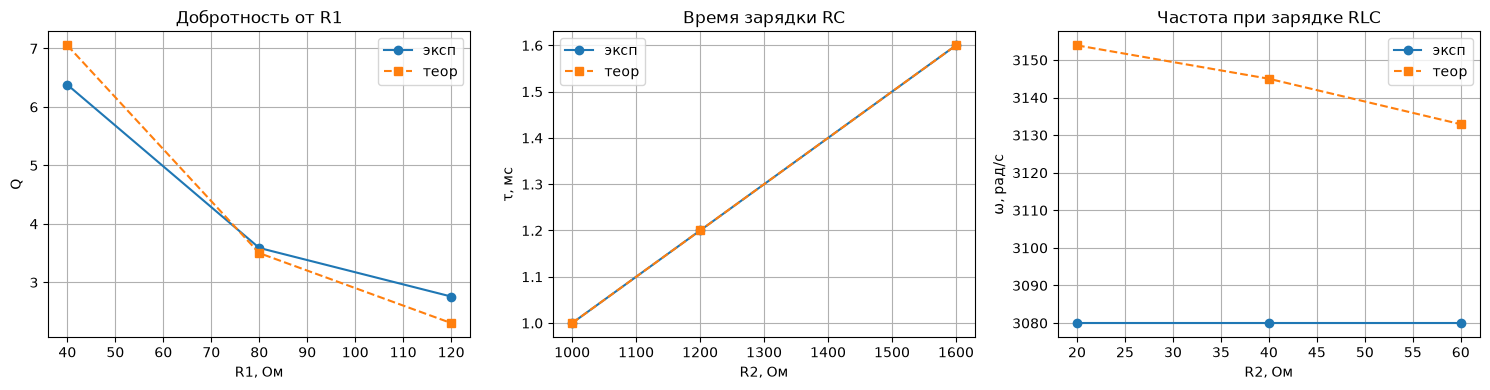

In [126]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Q(R1) — колебательная разрядка
axes[0].plot(table_osc["R1, Ом"], table_osc["Q эксп"], "o-", label="эксп")
axes[0].plot(table_osc["R1, Ом"], table_osc["Q теор"], "s--", label="теор")
axes[0].set_xlabel("R1, Ом"); axes[0].set_ylabel("Q")
axes[0].set_title("Добротность от R1"); axes[0].legend(); axes[0].grid(True)

# τ(R2) — обычная зарядка
axes[1].plot(table_rc["R2, Ом"], table_rc["τ эксп, мс"], "o-", label="эксп")
axes[1].plot(table_rc["R2, Ом"], table_rc["τ теор, мс"], "s--", label="теор")
axes[1].set_xlabel("R2, Ом"); axes[1].set_ylabel("τ, мс")
axes[1].set_title("Время зарядки RC"); axes[1].legend(); axes[1].grid(True)

# ω(R2) — колебательная зарядка
axes[2].plot(table_rlc["R2, Ом"], table_rlc["ω эксп, рад/с"], "o-", label="эксп")
axes[2].plot(table_rlc["R2, Ом"], table_rlc["ω теор, рад/с"], "s--", label="теор")
axes[2].set_xlabel("R2, Ом"); axes[2].set_ylabel("ω, рад/с")
axes[2].set_title("Частота при зарядке RLC"); axes[2].legend(); axes[2].grid(True)

plt.tight_layout()
plt.show()